In [49]:
import os

os.environ.setdefault(

    "CUBLAS_WORKSPACE_CONFIG",

    ":4096:8"

)

from pathlib import Path

from functools import partial

from datetime import datetime

import sys
import json
import gc
import time
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import optuna

from optuna.trial import TrialState

In [50]:
PROJECT_DIR = Path(
    r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca"
)

DATASET_DIR = (

    PROJECT_DIR

    / "dataset"

    / "raw"

    / "cassava_dataset"

)

CONFIGS_DIR = PROJECT_DIR / "configs"

REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR = PROJECT_DIR / "models"

EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

BASELINE_RUN_ID = "baseline_v1"

RUN_ID = "hyperband_v1"

BASELINE_MODELS_DIR = (

    MODELS_DIR / "baseline" / BASELINE_RUN_ID

)

BASELINE_REPORTS_DIR = (

    REPORTS_DIR / "baseline" / BASELINE_RUN_ID

)

HYPERBAND_REPORTS_DIR = (

    REPORTS_DIR / "hyperband" / RUN_ID

)

HYPERBAND_EXPERIMENTS_DIR = (

    EXPERIMENTS_DIR / "hyperband" / RUN_ID

)

for directory in [

    HYPERBAND_REPORTS_DIR,

    HYPERBAND_EXPERIMENTS_DIR

]:

    directory.mkdir(

        parents=True,

        exist_ok=True

    )

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0, str(PROJECT_DIR)
    )

In [51]:
from src.utils import (

    set_seed,

    get_device

)

from src.experiments import save_json

from src.optimization import (

    objective,

    create_hyperband_study,

    optimize_architecture,

    release_trial_memory

)

from src.preprocessing import build_transforms

from src.data_generator import create_fold_loaders

from src.model_factory import create_model

from src.metrics import calculate_class_weights

from src.trainer import (

    train_one_epoch,

    create_optimizer

)

In [52]:
def load_json(filepath):

    with open(

        filepath,

        "r",

        encoding="utf-8"

    ) as file:

        return json.load(file)


dataset_config = load_json(

    CONFIGS_DIR / "dataset_config.json"

)

training_config = load_json(

    CONFIGS_DIR / "training_config.json"

)

model_config = load_json(

    CONFIGS_DIR / "model_config.json"

)

pipeline_config = load_json(

    CONFIGS_DIR / "pipeline_config.json"

)

baseline_config = load_json(

    CONFIGS_DIR / "baseline_config.json"

)

SEED = training_config["seed"]

CLASS_MAPPING = dataset_config["class_mapping"]

NUM_CLASSES = len(CLASS_MAPPING)

ARCHITECTURES = training_config["architectures"]

DEVICE = get_device()

set_seed(SEED)

print("Device:", DEVICE)

print("Architectures:", ARCHITECTURES)

print("Classes:", CLASS_MAPPING)

Device: cuda
Architectures: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']
Classes: {'bacterial_blight': 0, 'brown_streak_disease': 1, 'green_mottle': 2, 'healthy': 3, 'mosaic_disease': 4}


In [53]:
assert DEVICE.type == "cuda"

assert len(ARCHITECTURES) == 5

assert NUM_CLASSES == 5

assert torch.are_deterministic_algorithms_enabled()

assert os.environ["CUBLAS_WORKSPACE_CONFIG"] in [

    ":4096:8",

    ":16:8"

]

print(
    "GPU:",
    torch.cuda.get_device_name(0)
)

print(
    "PyTorch:",
    torch.__version__
)

print(
    "Optuna:",
    optuna.__version__
)

print("Entorno verificado correctamente.")

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
PyTorch: 2.5.1+cu121
Optuna: 5.1.0
Entorno verificado correctamente.


In [54]:
df_splits = pd.read_csv(

    REPORTS_DIR / "dataset_splits.csv"

)

df_baseline = pd.read_csv(

    BASELINE_REPORTS_DIR

    / "baseline_results_verified.csv"

)

assert len(df_baseline) == 5

assert set(
    df_baseline["architecture"]
) == set(ARCHITECTURES)

assert (

    df_baseline["verified_skipped_steps"] == 0

).all()

display(

    df_baseline[[

        "architecture",

        "best_stage",

        "f1_macro",

        "accuracy",

        "total_minutes"

    ]]

)

,architecture,best_stage,f1_macro,accuracy,total_minutes
0,mobilenet_v3_large,feature_extraction,0.572956,0.707076,26.593112
1,efficientnet_b0,feature_extraction,0.552595,0.655451,43.078354
2,resnet50,feature_extraction,0.559891,0.680521,34.167810
3,vit_b_16,partial_finetuning,0.602832,0.727528,92.931073
4,swin_t,partial_finetuning,0.632792,0.740063,37.848155


In [55]:
hyperband_config = {

    "experiment_name": "hyperband_optimization",

    "run_id": RUN_ID,

    "framework": "Optuna",

    "sampler": "RandomSampler",

    "pruner": "HyperbandPruner",

    "direction": "maximize",

    "objective_metric": "f1_macro",

    "seed": SEED,

    "validation_fold": 1,

    "n_trials": 3,

    "min_resource": 1,

    "max_resource": 3,

    "reduction_factor": 3,

    "architectures": ARCHITECTURES,

    "architecture_stages": {

        "mobilenet_v3_large":
            "feature_extraction",

        "efficientnet_b0":
            "feature_extraction",

        "resnet50":
            "feature_extraction",

        "vit_b_16":
            "partial_finetuning",

        "swin_t":
            "partial_finetuning"

    },

    "default_dropout": model_config[
        "default_dropout"
    ],

    "effective_batch_size": 32,

    "num_workers": 0,

    "mixed_precision": True,

    "amp": training_config[
        "training"
    ]["amp"],

    "scheduler": pipeline_config[
        "scheduler"
    ],

    "loss": pipeline_config[
        "loss"
    ],

    "storage": "SQLite",

    "baseline_run_id": BASELINE_RUN_ID,

    "save_trial_checkpoints": False,

    "test_reserved": True

}

display(hyperband_config)

{'experiment_name': 'hyperband_optimization',
 'run_id': 'hyperband_v1',
 'framework': 'Optuna',
 'sampler': 'RandomSampler',
 'pruner': 'HyperbandPruner',
 'direction': 'maximize',
 'objective_metric': 'f1_macro',
 'seed': 42,
 'validation_fold': 1,
 'n_trials': 3,
 'min_resource': 1,
 'max_resource': 3,
 'reduction_factor': 3,
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'architecture_stages': {'mobilenet_v3_large': 'feature_extraction',
  'efficientnet_b0': 'feature_extraction',
  'resnet50': 'feature_extraction',
  'vit_b_16': 'partial_finetuning',
  'swin_t': 'partial_finetuning'},
 'default_dropout': 0.2,
 'effective_batch_size': 32,
 'num_workers': 0,
 'mixed_precision': True,
 'amp': {'dtype': 'float16',
  'init_scale': 1024.0,
  'growth_factor': 2.0,
  'backoff_factor': 0.5,
  'growth_interval': 2000},
 'scheduler': {'name': 'ReduceLROnPlateau',
  'factor': 0.5,
  'patience': 1,
  'min_lr': 1e-07},
 'loss': {'name': 'W

In [56]:
search_space = {

    "feature_extraction": {

        "classifier_lr": {

            "low": 1e-4,

            "high": 3e-3,

            "log": True

        },

        "weight_decay": {

            "low": 1e-6,

            "high": 1e-3,

            "log": True

        },

        "dropout": {

            "low": 0.0,

            "high": 0.4

        }

    },

    "partial_finetuning": {

        "classifier_lr": {

            "low": 3e-5,

            "high": 1e-3,

            "log": True

        },

        "backbone_lr": {

            "low": 1e-6,

            "high": 3e-5,

            "log": True

        },

        "weight_decay": {

            "low": 1e-6,

            "high": 1e-3,

            "log": True

        }

    }

}

display(search_space)

{'feature_extraction': {'classifier_lr': {'low': 0.0001,
   'high': 0.003,
   'log': True},
  'weight_decay': {'low': 1e-06, 'high': 0.001, 'log': True},
  'dropout': {'low': 0.0, 'high': 0.4}},
 'partial_finetuning': {'classifier_lr': {'low': 3e-05,
   'high': 0.001,
   'log': True},
  'backbone_lr': {'low': 1e-06, 'high': 3e-05, 'log': True},
  'weight_decay': {'low': 1e-06, 'high': 0.001, 'log': True}}}

In [61]:
for filename, config in [

    ("hyperband_config.json", hyperband_config),

    ("search_space.json", search_space)

]:

    filepath = CONFIGS_DIR / filename

    if filepath.exists():

        assert load_json(filepath) == config, (

            f"La configuración {filename} cambió. "

            "Revisa la versión experimental."

        )

    else:

        save_json(config, filepath)

print("Configuraciones guardadas.")

Configuraciones guardadas.


In [58]:
def calculate_sha256(filepath):

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as file:

        for chunk in iter(

            lambda: file.read(1024 * 1024),

            b""

        ):

            sha256.update(chunk)

    return sha256.hexdigest()


tracked_files = [

    CONFIGS_DIR / "dataset_config.json",

    CONFIGS_DIR / "preprocessing_config.json",

    CONFIGS_DIR / "training_config.json",

    CONFIGS_DIR / "model_config.json",

    CONFIGS_DIR / "pipeline_config.json",

    CONFIGS_DIR / "baseline_config.json",

    CONFIGS_DIR / "hyperband_config.json",

    CONFIGS_DIR / "search_space.json",

    REPORTS_DIR / "dataset_splits.csv",

    BASELINE_REPORTS_DIR
    / "baseline_results_verified.csv"

]

for filename in [

    "optimization.py",

    "trainer.py",

    "model_factory.py",

    "metrics.py",

    "preprocessing.py",

    "dataset.py",

    "data_generator.py",

    "utils.py"

]:

    tracked_files.append(

        PROJECT_DIR / "src" / filename

    )

for model_name in [

    "vit_b_16",

    "swin_t"

]:

    tracked_files.append(

        BASELINE_MODELS_DIR

        / model_name

        / "feature_extraction"

        / "best.pth"

    )

experiment_signature = {

    str(filepath.relative_to(PROJECT_DIR)):

        calculate_sha256(filepath)

    for filepath in tracked_files

}

signature_path = (

    HYPERBAND_EXPERIMENTS_DIR

    / "experiment_signature.json"

)

if signature_path.exists():

    assert (

        load_json(signature_path)

        == experiment_signature

    ), "La firma experimental ha cambiado."

else:

    save_json(

        experiment_signature,

        signature_path

    )

print(
    "Archivos verificados:",
    len(experiment_signature)
)

Archivos verificados: 20


In [59]:
from datetime import datetime

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

config_path = (
    CONFIGS_DIR / "hyperband_config.json"
)

previous_config = load_json(config_path)

previous_signature = load_json(signature_path)

# Verificar que la configuración solo cambió
# en el número de trials

expected_config = previous_config.copy()

expected_config["n_trials"] = 3

assert previous_config["n_trials"] == 6

assert hyperband_config == expected_config, (
    "Existen otros cambios en la configuración."
)

# Verificar que los archivos originales
# no hayan sufrido otros cambios

current_signature = {

    str(filepath.relative_to(PROJECT_DIR)):
        calculate_sha256(filepath)

    for filepath in tracked_files

}

assert current_signature == previous_signature, (
    "Existen cambios adicionales en los archivos."
)

# Respaldar configuración original

save_json(

    previous_config,

    HYPERBAND_EXPERIMENTS_DIR
    / f"hyperband_config_backup_{timestamp}.json"

)

# Respaldar firma original

save_json(

    previous_signature,

    HYPERBAND_EXPERIMENTS_DIR
    / f"signature_backup_{timestamp}.json"

)

# Guardar nueva configuración

save_json(
    hyperband_config,
    config_path
)

# Generar nueva firma

experiment_signature = {

    str(filepath.relative_to(PROJECT_DIR)):
        calculate_sha256(filepath)

    for filepath in tracked_files

}

save_json(
    experiment_signature,
    signature_path
)

# Documentar el cambio

budget_change = {

    "timestamp": timestamp,

    "run_id": RUN_ID,

    "previous_n_trials": 6,

    "new_n_trials": 3,

    "reason": (
        "Reducción del presupuesto computacional "
        "para cumplir el plazo del proyecto."
    ),

    "previous_trials_preserved": True,

    "search_space_changed": False,

    "dataset_splits_changed": False,

    "pruner_changed": False,

    "max_resource_changed": False,

    "previous_signature": previous_signature,

    "new_signature": experiment_signature

}

save_json(

    budget_change,

    HYPERBAND_EXPERIMENTS_DIR
    / f"budget_change_{timestamp}.json"

)

print("Presupuesto actualizado: 6 -> 3 trials")
print("Estudios anteriores conservados.")
print("Firma experimental actualizada.")

Presupuesto actualizado: 6 -> 3 trials
Estudios anteriores conservados.
Firma experimental actualizada.


In [62]:
CURRENT_FOLD = hyperband_config[
    "validation_fold"
]

df_train = df_splits[

    (df_splits["split"] == "development")

    & (df_splits["fold"] != CURRENT_FOLD)

].copy()

df_val = df_splits[

    (df_splits["split"] == "development")

    & (df_splits["fold"] == CURRENT_FOLD)

].copy()

df_test = df_splits[

    df_splits["split"] == "test"

].copy()

assert df_splits["filepath"].is_unique

assert df_splits["sha256"].notna().all()

assert set(
    df_train["sha256"]
).isdisjoint(
    df_val["sha256"]
)

assert set(
    df_train["sha256"]
).isdisjoint(
    df_test["sha256"]
)

assert set(
    df_val["sha256"]
).isdisjoint(
    df_test["sha256"]
)

print("Training:", len(df_train))

print("Validation:", len(df_val))

print("Test reservado:", len(df_test))

Training: 12124
Validation: 6063
Test reservado: 3210


In [63]:
from src.dataset import CassavaDataset

from src.data_generator import create_dataloader

set_seed(SEED)

train_transform, _ = build_transforms(

    CONFIGS_DIR / "preprocessing_config.json"

)

df_smoke = df_train.sample(

    n=96,

    random_state=SEED

)

smoke_dataset = CassavaDataset(

    dataframe=df_smoke,

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    transform=train_transform

)

smoke_loader = create_dataloader(

    dataset=smoke_dataset,

    batch_size=16,

    shuffle=True,

    num_workers=0,

    seed=SEED

)

smoke_model = create_model(

    model_name="mobilenet_v3_large",

    num_classes=NUM_CLASSES,

    pretrained=True,

    dropout=0.2,

    mode="feature_extraction",

    device=DEVICE

)

smoke_optimizer = create_optimizer(

    model=smoke_model,

    model_name="mobilenet_v3_large",

    classifier_lr=1e-3,

    weight_decay=1e-4

)

smoke_weights = calculate_class_weights(

    df_train,

    CLASS_MAPPING

).to(DEVICE)

smoke_criterion = torch.nn.CrossEntropyLoss(

    weight=smoke_weights,

    reduction="sum"

)

smoke_scaler = torch.amp.GradScaler(

    "cuda",

    init_scale=1024.0,

    enabled=True

)

smoke_metrics = train_one_epoch(

    model=smoke_model,

    model_name="mobilenet_v3_large",

    dataloader=smoke_loader,

    optimizer=smoke_optimizer,

    criterion=smoke_criterion,

    scaler=smoke_scaler,

    device=DEVICE,

    num_classes=NUM_CLASSES,

    accumulation_steps=2,

    use_amp=True

)

display(

    pd.DataFrame([smoke_metrics])

)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,optimizer_steps,expected_optimizer_steps,skipped_optimizer_steps,skipped_steps_pct,amp_scale
0,0.104167,0.154189,0.151282,0.105176,0.092777,0.151282,1.65092,2.038859,96,3,3,0,0.0,1024.0


In [64]:
assert smoke_metrics[
    "expected_optimizer_steps"
] == 3

assert smoke_metrics[
    "optimizer_steps"
] == 3

assert smoke_metrics[
    "skipped_optimizer_steps"
] == 0

internal_steps = [

    int(state["step"].item())

    for state in smoke_optimizer.state.values()

    if "step" in state

]

assert len(internal_steps) > 0

assert min(internal_steps) == 3

assert max(internal_steps) == 3

print("Smoke Test: SATISFACTORIO")

print("Expected steps: 3")

print("Recorded steps: 3")

print("AdamW internal steps: 3")

save_json(

    {

        "expected_steps": 3,

        "recorded_steps": 3,

        "adamw_internal_steps": 3,

        "status": "passed"

    },

    HYPERBAND_EXPERIMENTS_DIR

    / "smoke_test.json"

)

del smoke_model
del smoke_optimizer
del smoke_scaler
del smoke_criterion
del smoke_loader
del smoke_dataset
del smoke_weights

release_trial_memory()

Smoke Test: SATISFACTORIO
Expected steps: 3
Recorded steps: 3
AdamW internal steps: 3


In [65]:
DATABASE_PATH = (

    HYPERBAND_EXPERIMENTS_DIR

    / "hyperband_studies.db"

)

STORAGE_URL = (

    f"sqlite:///{DATABASE_PATH.as_posix()}"

)

print("Database:", DATABASE_PATH)

print("Storage:", STORAGE_URL)

Database: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\experiments\hyperband\hyperband_v1\hyperband_studies.db
Storage: sqlite:///C:/Users/Joseph (YO)/JGM/U/Semestre_10/InteligenciaArtificial/Proyecto_Yuca/experiments/hyperband/hyperband_v1/hyperband_studies.db


In [66]:
studies = {}

for model_name in ARCHITECTURES:

    studies[model_name] = (

        create_hyperband_study(

            model_name=model_name,

            storage_url=STORAGE_URL,

            hyperband_config=hyperband_config

        )

    )

print(
    "Estudios disponibles:",
    len(studies)
)

[I 2026-11-25 21:18:13,166] Using an existing study with `study_name='hyperband_v1_mobilenet_v3_large'` instead of creating a new one.
[I 2026-11-25 21:18:13,218] Using an existing study with `study_name='hyperband_v1_efficientnet_b0'` instead of creating a new one.
[I 2026-11-25 21:18:13,258] Using an existing study with `study_name='hyperband_v1_resnet50'` instead of creating a new one.
[I 2026-11-25 21:18:13,300] Using an existing study with `study_name='hyperband_v1_vit_b_16'` instead of creating a new one.
[I 2026-11-25 21:18:13,350] Using an existing study with `study_name='hyperband_v1_swin_t'` instead of creating a new one.


Estudios disponibles: 5


In [67]:
def get_studies_status(studies):

    rows = []

    for model_name, study in studies.items():

        trials = study.trials

        rows.append({

            "architecture": model_name,

            "total_trials": len(trials),

            "completed": sum(

                t.state == TrialState.COMPLETE

                for t in trials

            ),

            "pruned": sum(

                t.state == TrialState.PRUNED

                for t in trials

            ),

            "failed": sum(

                t.state == TrialState.FAIL

                for t in trials

            ),

            "running": sum(

                t.state == TrialState.RUNNING

                for t in trials

            )

        })

    return pd.DataFrame(rows)


display(
    get_studies_status(studies)
)

,architecture,total_trials,completed,pruned,failed,running
0,mobilenet_v3_large,7,2,4,1,0
1,efficientnet_b0,1,0,0,1,0
2,resnet50,1,0,0,0,0
3,vit_b_16,1,0,0,0,0
4,swin_t,1,0,0,0,0


In [68]:
def build_objective(model_name):

    return partial(

        objective,

        model_name=model_name,

        df_splits=df_splits,

        dataset_dir=DATASET_DIR,

        class_mapping=CLASS_MAPPING,

        preprocessing_config_path=(

            CONFIGS_DIR

            / "preprocessing_config.json"

        ),

        training_config=training_config,

        hyperband_config=hyperband_config,

        search_space=search_space,

        baseline_models_dir=BASELINE_MODELS_DIR,

        device=DEVICE

    )

In [69]:
def export_study_results(studies):

    all_trials = []

    results = []

    for model_name, study in studies.items():

        df_trials = study.trials_dataframe()

        if not df_trials.empty:

            df_trials.insert(

                0,

                "architecture",

                model_name

            )

            all_trials.append(df_trials)

            df_trials.to_csv(

                HYPERBAND_REPORTS_DIR

                / f"{model_name}_trials.csv",

                index=False,

                encoding="utf-8-sig"

            )

        completed_trials = [

            t for t in study.trials

            if t.state == TrialState.COMPLETE

        ]

        if not completed_trials:

            continue

        best_trial = study.best_trial

        results.append({

            "architecture": model_name,

            "stage": hyperband_config[
                "architecture_stages"
            ][model_name],

            "best_trial": best_trial.number,

            "best_f1_macro": best_trial.value,

            "best_epoch": best_trial.user_attrs[
                "best_epoch"
            ],

            "completed_trials": len(
                completed_trials
            ),

            "pruned_trials": sum(

                t.state == TrialState.PRUNED

                for t in study.trials

            ),

            "total_minutes": sum(

                t.user_attrs.get(
                    "total_minutes", 0
                )

                for t in study.trials

            ),

            **best_trial.user_attrs[
                "resolved_params"
            ]

        })

    if all_trials:

        pd.concat(

            all_trials,

            ignore_index=True

        ).to_csv(

            HYPERBAND_REPORTS_DIR

            / "all_trials.csv",

            index=False,

            encoding="utf-8-sig"

        )

    df_results = pd.DataFrame(results)

    if not df_results.empty:

        df_results.to_csv(

            HYPERBAND_REPORTS_DIR

            / "hyperband_results.csv",

            index=False,

            encoding="utf-8-sig"

        )

    return df_results

In [70]:
for model_name, study in studies.items():

    if len(study.trials) > 0:

        continue

    stage = hyperband_config[
        "architecture_stages"
    ][model_name]

    params = {

        "classifier_lr": baseline_config[
            stage
        ]["classifier_lr"],

        "weight_decay": baseline_config[
            "weight_decay"
        ]

    }

    if stage == "feature_extraction":

        params["dropout"] = baseline_config[
            "dropout"
        ]

    else:

        params["backbone_lr"] = baseline_config[
            stage
        ]["backbone_lr"]

    study.enqueue_trial(params)

    print(
        model_name,
        params
    )

In [71]:
pilot_model = "mobilenet_v3_large"

pilot_study = studies[pilot_model]

optimize_architecture(

    study=pilot_study,

    objective_function=build_objective(

        pilot_model

    ),

    target_trials=1

)

df_pilot_results = export_study_results(
    studies
)

display(df_pilot_results)

Study: hyperband_v1_mobilenet_v3_large
Trials terminados: 6
Trials pendientes: 0


,architecture,stage,best_trial,best_f1_macro,best_epoch,completed_trials,pruned_trials,total_minutes,classifier_lr,weight_decay,dropout
0,mobilenet_v3_large,feature_extraction,2,0.578212,3,2,4,61.210128,0.000766,0.000003,0.062398


In [72]:
pilot_trial = pilot_study.best_trial

df_pilot_history = pd.DataFrame(

    pilot_trial.user_attrs[
        "epoch_history"
    ]

)

display(df_pilot_history.round(4))

print(

    "Mejor F1 Macro:",

    pilot_trial.value

)

print(

    "Tiempo total (min):",

    pilot_trial.user_attrs[
        "total_minutes"
    ]

)

assert (

    df_pilot_history[
        "actual_optimizer_steps"
    ]

    <=

    df_pilot_history[
        "expected_optimizer_steps"
    ]

).all()

,epoch,train_loss,train_f1_macro,val_loss,val_f1_macro,val_accuracy,expected_optimizer_steps,actual_optimizer_steps,skipped_optimizer_steps,amp_scale,epoch_seconds
0,1,1.0788,0.5172,1.0454,0.5482,0.6785,379,379,0,1024.0,352.2539
1,2,0.9295,0.5859,1.0836,0.4915,0.5910,379,379,0,1024.0,356.4668
2,3,0.8829,0.6067,1.0092,0.5782,0.7063,379,379,0,1024.0,369.5172


Mejor F1 Macro: 0.5782121416987023
Tiempo total (min): 17.986600604999996


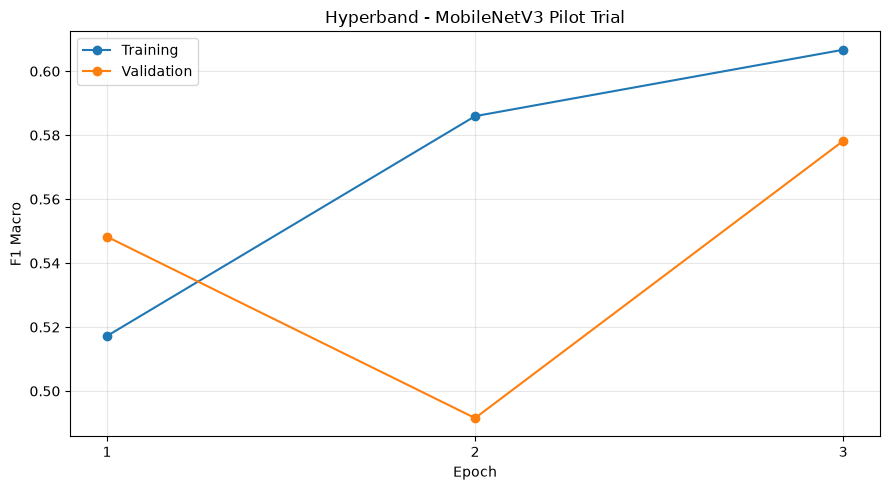

In [73]:
plt.figure(figsize=(9, 5))

plt.plot(

    df_pilot_history["epoch"],

    df_pilot_history["train_f1_macro"],

    marker="o",

    label="Training"

)

plt.plot(

    df_pilot_history["epoch"],

    df_pilot_history["val_f1_macro"],

    marker="o",

    label="Validation"

)

plt.xlabel("Epoch")

plt.ylabel("F1 Macro")

plt.title("Hyperband - MobileNetV3 Pilot Trial")

plt.xticks(
    df_pilot_history["epoch"]
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [74]:
execution_start = time.perf_counter()

optimization_errors = []

for model_name in ARCHITECTURES:

    print("\n" + "=" * 70)

    print(f"HYPERBAND: {model_name}")

    print("=" * 70)

    try:

        optimize_architecture(

            study=studies[model_name],

            objective_function=build_objective(

                model_name

            ),

            target_trials=hyperband_config[
                "n_trials"
            ]

        )

    except KeyboardInterrupt:

        print(
            "Optimización interrumpida."
        )

        break

    except Exception as error:

        optimization_errors.append({

            "architecture": model_name,

            "error": str(error)

        })

        print(
            f"Error: {error}"
        )

        break

    finally:

        release_trial_memory()

        export_study_results(studies)

        save_json(

            optimization_errors,

            HYPERBAND_EXPERIMENTS_DIR

            / "optimization_errors.json"

        )

execution_minutes = (

    time.perf_counter() - execution_start

) / 60

print(

    "Tiempo de esta ejecución:",

    round(execution_minutes, 2),

    "minutos"

)

display(
    get_studies_status(studies)
)


HYPERBAND: mobilenet_v3_large
Study: hyperband_v1_mobilenet_v3_large
Trials terminados: 6
Trials pendientes: 0

HYPERBAND: efficientnet_b0
Study: hyperband_v1_efficientnet_b0
Trials terminados: 0
Trials pendientes: 3
efficientnet_b0 | Trial 1
Stage: feature_extraction
Params: {'classifier_lr': 0.0003574712922600243, 'weight_decay': 0.0007114476009343421, 'dropout': 0.292797576724562}
Epoch 1/3 | Train F1: 0.4503 | Val F1: 0.4796 | Time: 5.44 min
Epoch 2/3 | Train F1: 0.5200 | Val F1: 0.5078 | Time: 6.06 min
Epoch 3/3 | Train F1: 0.5401 | Val F1: 0.5149 | Time: 6.27 min


[I 2026-11-25 21:36:29,707] Trial 1 finished with value: 0.5149020098649071 and parameters: {'classifier_lr': 0.0003574712922600243, 'weight_decay': 0.0007114476009343421, 'dropout': 0.292797576724562}. Best is trial 1 with value: 0.5149020098649071.


efficientnet_b0 | Trial 2
Stage: feature_extraction
Params: {'classifier_lr': 0.0007661100707771367, 'weight_decay': 2.9380279387035354e-06, 'dropout': 0.062397808134481064}
Epoch 1/3 | Train F1: 0.4905 | Val F1: 0.5040 | Time: 5.96 min
Trial 2 descartado en época 1.


[I 2026-11-25 21:42:28,929] Trial 2 pruned. 


efficientnet_b0 | Trial 3
Stage: feature_extraction
Params: {'classifier_lr': 0.00012184186502221769, 'weight_decay': 0.0003967605077052988, 'dropout': 0.24044600469728353}
Epoch 1/3 | Train F1: 0.3899 | Val F1: 0.4460 | Time: 5.98 min
Epoch 2/3 | Train F1: 0.4938 | Val F1: 0.4631 | Time: 5.92 min
Epoch 3/3 | Train F1: 0.5114 | Val F1: 0.4865 | Time: 5.74 min


[I 2026-11-25 22:00:08,899] Trial 3 finished with value: 0.4864792444440102 and parameters: {'classifier_lr': 0.00012184186502221769, 'weight_decay': 0.0003967605077052988, 'dropout': 0.24044600469728353}. Best is trial 1 with value: 0.5149020098649071.


... (16 outputs left out)

swin_t | Trial 2
Stage: partial_finetuning
Params: {'classifier_lr': 0.00024479668704186603, 'weight_decay': 2.9380279387035354e-06, 'backbone_lr': 1.6998978382700769e-06, 'dropout': 0.2}
Epoch 1/3 | Train F1: 0.5891 | Val F1: 0.6034 | Time: 9.25 min
Trial 2 descartado en época 1.


[I 2026-11-26 00:45:31,174] Trial 2 pruned. 


Tiempo de esta ejecución: 206.84 minutos


,architecture,total_trials,completed,pruned,failed,running
0,mobilenet_v3_large,7,2,4,1,0
1,efficientnet_b0,4,2,1,1,0
2,resnet50,3,2,1,0,0
3,vit_b_16,3,3,0,0,0
4,swin_t,3,2,1,0,0


In [46]:
display(
    get_studies_status(studies)
)

,architecture,total_trials,completed,pruned,failed,running
0,mobilenet_v3_large,7,2,4,1,0
1,efficientnet_b0,1,0,0,1,0
2,resnet50,1,0,0,0,0
3,vit_b_16,1,0,0,0,0
4,swin_t,1,0,0,0,0


In [75]:
for study in studies.values():

    for trial in study.get_trials(

        states=(TrialState.RUNNING,)

    ):

        study.tell(

            trial.number,

            state=TrialState.FAIL

        )

        print(

            "Trial interrumpido:",

            study.study_name,

            trial.number

        )

In [76]:
df_study_status = get_studies_status(
    studies
)

df_study_status["finished_trials"] = (

    df_study_status["completed"]

    + df_study_status["pruned"]

)

display(df_study_status)

df_study_status.to_csv(

    HYPERBAND_REPORTS_DIR

    / "study_status.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,total_trials,completed,pruned,failed,running,finished_trials
0,mobilenet_v3_large,7,2,4,1,0,6
1,efficientnet_b0,4,2,1,1,0,3
2,resnet50,3,2,1,0,0,3
3,vit_b_16,3,3,0,0,0,3
4,swin_t,3,2,1,0,0,3


In [77]:
df_hyperband_results = export_study_results(

    studies

)

display(

    df_hyperband_results

    .sort_values(

        "best_f1_macro",

        ascending=False

    )

    .round(6)

)

,architecture,stage,best_trial,best_f1_macro,best_epoch,completed_trials,pruned_trials,total_minutes,classifier_lr,weight_decay,dropout,backbone_lr
4,swin_t,partial_finetuning,1,0.670233,3,2,1,51.931019,0.000112,0.000711,0.200000,0.000012
3,vit_b_16,partial_finetuning,0,0.612145,3,3,0,77.795299,0.000100,0.000100,0.200000,0.000010
0,mobilenet_v3_large,feature_extraction,2,0.578212,3,2,4,61.210128,0.000766,0.000003,0.062398,NaN
2,resnet50,feature_extraction,0,0.559891,3,2,1,35.557971,0.001000,0.000100,0.200000,NaN
1,efficientnet_b0,feature_extraction,1,0.514902,3,2,1,46.744643,0.000357,0.000711,0.292798,NaN


In [78]:
df_comparison = df_baseline[[

    "architecture",

    "best_stage",

    "f1_macro"

]].rename(

    columns={

        "f1_macro": "baseline_f1_macro",

        "best_stage": "baseline_stage"

    }

)

df_comparison = df_comparison.merge(

    df_hyperband_results[[

        "architecture",

        "stage",

        "best_f1_macro",

        "best_epoch",

        "total_minutes"

    ]],

    on="architecture",

    how="inner",

    validate="one_to_one"

)

df_comparison["gain"] = (

    df_comparison["best_f1_macro"]

    - df_comparison["baseline_f1_macro"]

)

df_comparison["gain_pp"] = (

    df_comparison["gain"] * 100

)

df_comparison["improved"] = (

    df_comparison["gain"] > 0

)

display(
    df_comparison.round(4)
)

df_comparison.to_csv(

    HYPERBAND_REPORTS_DIR

    / "baseline_vs_hyperband.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,baseline_stage,baseline_f1_macro,stage,best_f1_macro,best_epoch,total_minutes,gain,gain_pp,improved
0,mobilenet_v3_large,feature_extraction,0.5730,feature_extraction,0.5782,3,61.2101,0.0053,0.5256,True
1,efficientnet_b0,feature_extraction,0.5526,feature_extraction,0.5149,3,46.7446,-0.0377,-3.7693,False
2,resnet50,feature_extraction,0.5599,feature_extraction,0.5599,3,35.5580,0.0000,0.0000,False
3,vit_b_16,partial_finetuning,0.6028,partial_finetuning,0.6121,3,77.7953,0.0093,0.9313,True
4,swin_t,partial_finetuning,0.6328,partial_finetuning,0.6702,3,51.9310,0.0374,3.7440,True


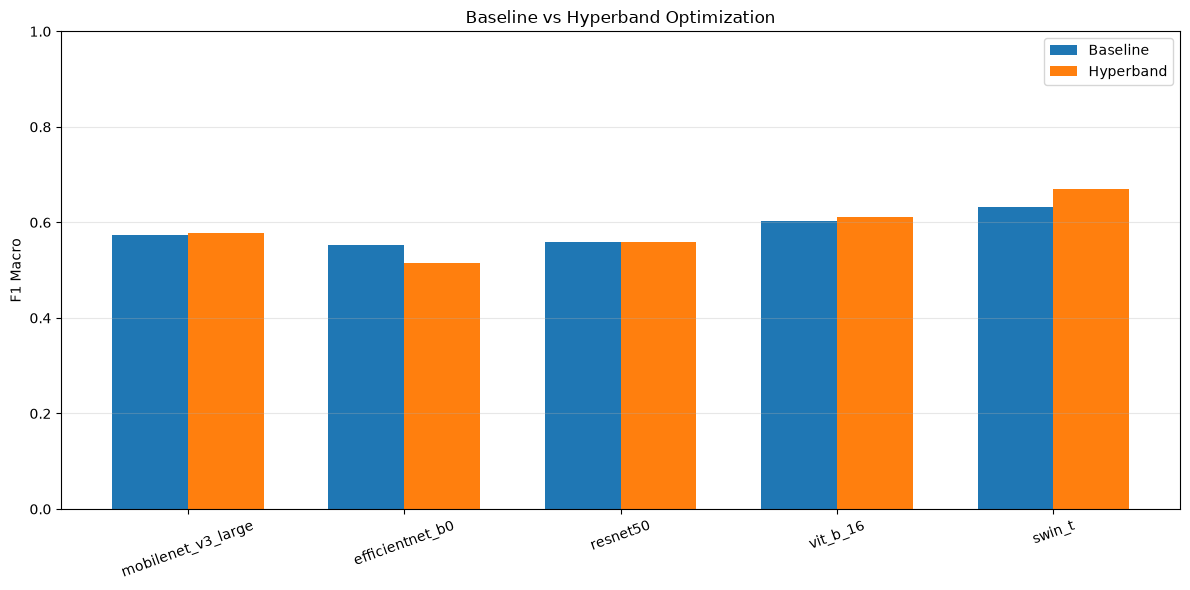

In [79]:
x = np.arange(
    len(df_comparison)
)

width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(

    x - width / 2,

    df_comparison["baseline_f1_macro"],

    width,

    label="Baseline"

)

plt.bar(

    x + width / 2,

    df_comparison["best_f1_macro"],

    width,

    label="Hyperband"

)

plt.xticks(

    x,

    df_comparison["architecture"],

    rotation=20

)

plt.ylabel("F1 Macro")

plt.title("Baseline vs Hyperband Optimization")

plt.ylim(0, 1)

plt.legend()

plt.grid(

    axis="y",

    alpha=0.3

)

plt.tight_layout()

plt.savefig(

    HYPERBAND_REPORTS_DIR

    / "baseline_vs_hyperband.png",

    dpi=200

)

plt.show()

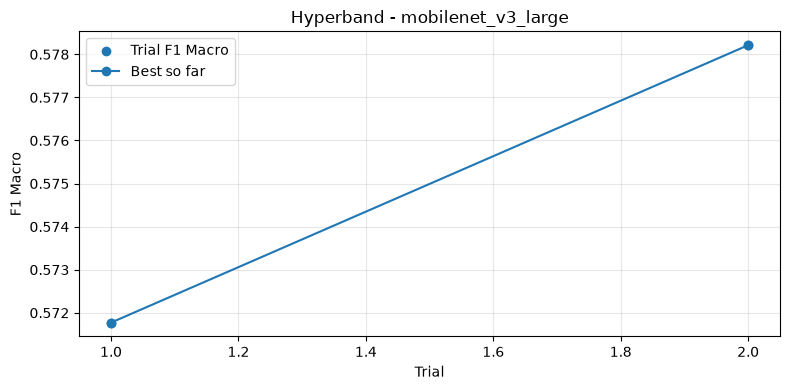

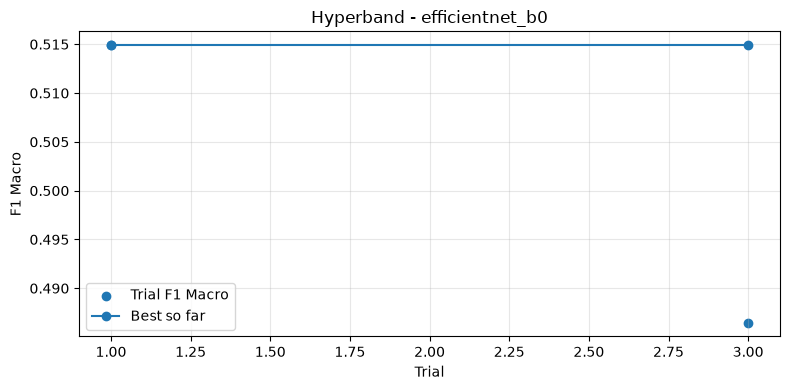

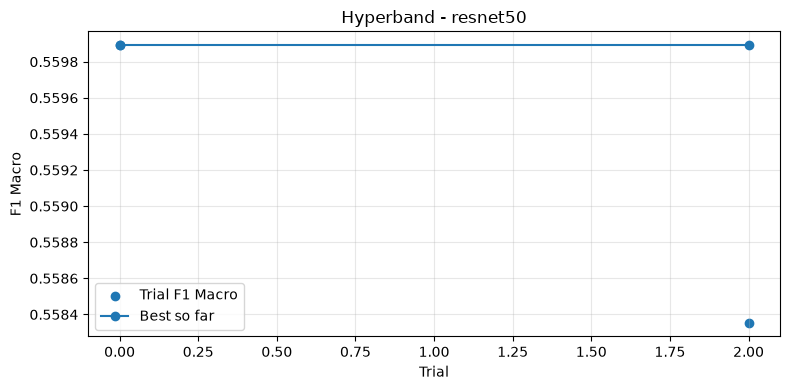

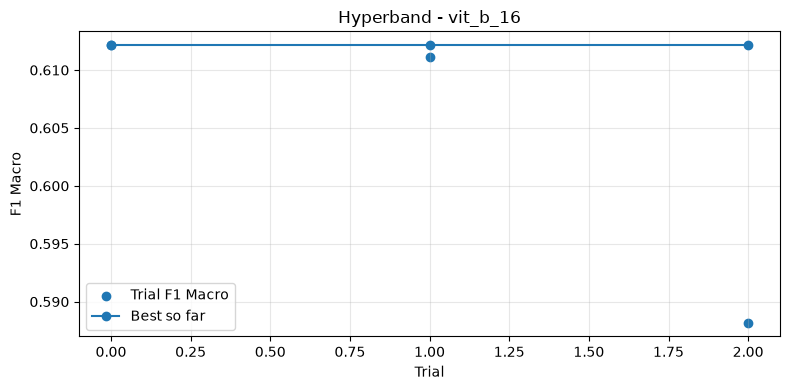

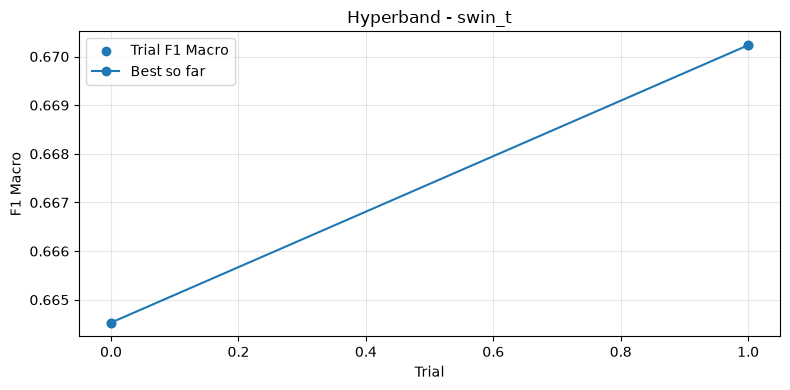

In [80]:
for model_name, study in studies.items():

    completed = [

        trial

        for trial in study.trials

        if trial.state == TrialState.COMPLETE

    ]

    if not completed:

        continue

    trial_numbers = [

        trial.number

        for trial in completed

    ]

    scores = [

        trial.value

        for trial in completed

    ]

    best_so_far = np.maximum.accumulate(
        scores
    )

    plt.figure(figsize=(8, 4))

    plt.scatter(

        trial_numbers,

        scores,

        label="Trial F1 Macro"

    )

    plt.plot(

        trial_numbers,

        best_so_far,

        marker="o",

        label="Best so far"

    )

    plt.title(

        f"Hyperband - {model_name}"

    )

    plt.xlabel("Trial")

    plt.ylabel("F1 Macro")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        HYPERBAND_REPORTS_DIR

        / f"{model_name}_optimization_history.png",

        dpi=200

    )

    plt.show()

In [81]:
pruning_summary = []

for model_name, study in studies.items():

    trials = [

        trial

        for trial in study.trials

        if trial.state in [

            TrialState.COMPLETE,

            TrialState.PRUNED

        ]

    ]

    max_possible_epochs = (

        len(trials)

        * hyperband_config["max_resource"]

    )

    executed_epochs = sum(

        trial.user_attrs.get(
            "epochs_completed", 0
        )

        for trial in trials

    )

    saved_epochs = (

        max_possible_epochs

        - executed_epochs

    )

    pruning_summary.append({

        "architecture": model_name,

        "finished_trials": len(trials),

        "max_possible_epochs": max_possible_epochs,

        "executed_epochs": executed_epochs,

        "saved_epochs": saved_epochs,

        "resource_saving_pct": (

            saved_epochs

            / max_possible_epochs

            * 100

            if max_possible_epochs > 0

            else 0

        )

    })

df_pruning_summary = pd.DataFrame(

    pruning_summary

)

display(
    df_pruning_summary.round(2)
)

df_pruning_summary.to_csv(

    HYPERBAND_REPORTS_DIR

    / "pruning_summary.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,finished_trials,max_possible_epochs,executed_epochs,saved_epochs,resource_saving_pct
0,mobilenet_v3_large,6,18,10,8,44.44
1,efficientnet_b0,3,9,7,2,22.22
2,resnet50,3,9,7,2,22.22
3,vit_b_16,3,9,9,0,0.00
4,swin_t,3,9,7,2,22.22


In [82]:
optimized_hyperparameters = {}

for model_name in ARCHITECTURES:

    study = studies[model_name]

    baseline_row = df_baseline[

        df_baseline["architecture"]

        == model_name

    ].iloc[0]

    baseline_score = float(

        baseline_row["f1_macro"]

    )

    best_trial = study.best_trial

    optimized_score = float(
        best_trial.value
    )

    selected_stage = hyperband_config[
        "architecture_stages"
    ][model_name]

    # Configuración original completa

    selected_config = {

        "feature_extraction": {

            "epochs": baseline_config[
                "feature_extraction"
            ]["epochs"],

            "classifier_lr": baseline_config[
                "feature_extraction"
            ]["classifier_lr"],

            "weight_decay": baseline_config[
                "weight_decay"
            ],

            "dropout": baseline_config[
                "dropout"
            ]

        },

        "partial_finetuning": {

            "epochs": baseline_config[
                "partial_finetuning"
            ]["epochs"],

            "classifier_lr": baseline_config[
                "partial_finetuning"
            ]["classifier_lr"],

            "backbone_lr": baseline_config[
                "partial_finetuning"
            ]["backbone_lr"],

            "weight_decay": baseline_config[
                "weight_decay"
            ],

            "dropout": baseline_config[
                "dropout"
            ]

        }

    }

    if optimized_score > baseline_score:

        source = "hyperband"

        selected_config[
            selected_stage
        ].update(

            best_trial.user_attrs[
                "resolved_params"
            ]

        )

        selected_config[
            selected_stage
        ]["epochs"] = int(

            best_trial.user_attrs[
                "best_epoch"
            ]

        )

        selected_score = optimized_score

    else:

        source = "baseline"

        selected_score = baseline_score

    optimized_hyperparameters[model_name] = {

        "source": source,

        "selected_stage": selected_stage,

        "baseline_f1_macro": baseline_score,

        "hyperband_f1_macro": optimized_score,

        "selected_f1_macro": selected_score,

        "optimization_fold": CURRENT_FOLD,

        "training_config": selected_config,

        "model_settings": training_config[
            "model_settings"
        ][model_name]

    }

display(
    optimized_hyperparameters
)

{'mobilenet_v3_large': {'source': 'hyperband',
  'selected_stage': 'feature_extraction',
  'baseline_f1_macro': 0.5729563773258665,
  'hyperband_f1_macro': 0.5782121416987023,
  'selected_f1_macro': 0.5782121416987023,
  'optimization_fold': 1,
  'training_config': {'feature_extraction': {'epochs': 3,
    'classifier_lr': 0.0007661100707771367,
    'weight_decay': 2.9380279387035354e-06,
    'dropout': 0.062397808134481064},
   'partial_finetuning': {'epochs': 2,
    'classifier_lr': 0.0001,
    'backbone_lr': 1e-05,
    'weight_decay': 0.0001,
    'dropout': 0.2}},
  'model_settings': {'batch_size': 16, 'gradient_accumulation_steps': 2}},
 'efficientnet_b0': {'source': 'baseline',
  'selected_stage': 'feature_extraction',
  'baseline_f1_macro': 0.5525949727690953,
  'hyperband_f1_macro': 0.5149020098649071,
  'selected_f1_macro': 0.5525949727690953,
  'optimization_fold': 1,
  'training_config': {'feature_extraction': {'epochs': 3,
    'classifier_lr': 0.001,
    'weight_decay': 0.000

In [83]:
assert len(
    optimized_hyperparameters
) == 5

save_json(

    optimized_hyperparameters,

    CONFIGS_DIR

    / "optimized_hyperparameters.json"

)

save_json(

    optimized_hyperparameters,

    HYPERBAND_EXPERIMENTS_DIR

    / "optimized_hyperparameters.json"

)

print(
    "Hiperparámetros seleccionados y guardados."
)

Hiperparámetros seleccionados y guardados.


In [84]:
df_study_status = get_studies_status(
    studies
)

assert len(df_study_status) == 5

assert (

    df_study_status["completed"]

    + df_study_status["pruned"]

    >= hyperband_config["n_trials"]

).all()

assert (

    df_study_status["completed"] > 0

).all()

assert (

    df_study_status["running"] == 0

).all()

assert len(
    optimized_hyperparameters
) == 5

assert hyperband_config[
    "test_reserved"
]

for model_name, study in studies.items():

    for trial in study.trials:

        for epoch in trial.user_attrs.get(

            "epoch_history",

            []

        ):

            assert (

                0

                <= epoch["actual_optimizer_steps"]

                <= epoch["expected_optimizer_steps"]

            )

print("Validaciones experimentales satisfactorias.")

Validaciones experimentales satisfactorias.


In [85]:
hyperband_summary = {

    "phase": "phase_2_part_5",

    "experiment": "hyperband_optimization",

    "run_id": RUN_ID,

    "status": "completed",

    "architectures_optimized": 5,

    "sampler": "RandomSampler",

    "pruner": "HyperbandPruner",

    "validation_fold": CURRENT_FOLD,

    "completed_trials": int(

        df_study_status["completed"].sum()

    ),

    "pruned_trials": int(

        df_study_status["pruned"].sum()

    ),

    "failed_trials": int(

        df_study_status["failed"].sum()

    ),

    "executed_epochs": int(

        df_pruning_summary[
            "executed_epochs"
        ].sum()

    ),

    "saved_epochs": int(

        df_pruning_summary[
            "saved_epochs"
        ].sum()

    ),

    "architectures_improved": int(

        df_comparison["improved"].sum()

    ),

    "total_minutes": float(

        df_hyperband_results[
            "total_minutes"
        ].sum()

    ),

    "test_used": False,

    "timestamp": datetime.now().isoformat()

}

save_json(

    hyperband_summary,

    HYPERBAND_EXPERIMENTS_DIR

    / "hyperband_summary.json"

)

print("=" * 70)

print("FASE 2 - PARTE 5 COMPLETADA")

print("=" * 70)

display(hyperband_summary)

release_trial_memory()

FASE 2 - PARTE 5 COMPLETADA


{'phase': 'phase_2_part_5',
 'experiment': 'hyperband_optimization',
 'run_id': 'hyperband_v1',
 'status': 'completed',
 'architectures_optimized': 5,
 'sampler': 'RandomSampler',
 'pruner': 'HyperbandPruner',
 'validation_fold': 1,
 'completed_trials': 11,
 'pruned_trials': 7,
 'failed_trials': 2,
 'executed_epochs': 40,
 'saved_epochs': 14,
 'architectures_improved': 3,
 'total_minutes': 273.2390612700001,
 'test_used': False,
 'timestamp': '2026-11-26T00:52:51.983826'}